# SS3 Part B: Applying the Final Model to STADIOEquities Client Data

**Module:** CAP182 Capstone SS3 | **Client:** STADIOEquities | **Author:** Tracy-lee (21620896)

This notebook applies the **final method chosen in SS2 a Random Forest classifier** to the
**newly received STADIOEquities client data extract**, to predict **early account activation**
(`activated_30d`): whether a newly registered account makes a qualifying first deposit within
30 days of registration.

The notebook is organised into the five required components, each clearly marked:

1. **Dataset loading**
2. **Dataset preprocessing**
3. **Model training**
4. **Model validation**
5. **Results visualisation**

> The public UCI Bank Marketing dataset used in SS2 was a *viability proxy*. Here we apply the
> same modelling approach to STADIOEquities' own data, delivered against the SS1 data request.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

# Locate the client data folder whether the notebook is run from the repo root
# or from a sub-folder (searches a few sensible locations).
_candidates = [Path("data/client"), Path("../data/client"),
               Path("../../data/client"), Path(".")]
DATA = next((c for c in _candidates
             if (c / "table1_account_registration_funding.csv").exists()), Path("data/client"))
print("Libraries loaded. Reading client data from:", DATA.resolve())

Libraries loaded. Reading client data from: /Users/kennedy/Tracy/Assignment 4/STADIOEquities-Capstone/data/client


---
## 1. Dataset loading

The client supplied **four tables** (matching the SS1 data request), joined on the surrogate key
`account_id`:

| Table | Grain | Contents |
|-------|-------|----------|
| `table1_account_registration_funding` | one row / account | registration, KYC, onboarding, **target `activated_30d`** |
| `table2_onboarding_first_session_events` | one row / event | first-3-day app/web behaviour |
| `table3_client_basic_information` | one row / account | demographics captured at sign-up |
| `table4_marketing_acquisition` | one row / account | acquisition channel, cost, nudges |

Table 1 contains **7 duplicate `account_id`s**, which we drop immediately so every account appears
once. We then report the number of instances, the classes, and the class imbalance.

In [2]:
t1 = pd.read_csv(DATA / "table1_account_registration_funding.csv")
t2 = pd.read_csv(DATA / "table2_onboarding_first_session_events.csv")
t3 = pd.read_csv(DATA / "table3_client_basic_information.csv")
t4 = pd.read_csv(DATA / "table4_marketing_acquisition.csv")

print("Raw shapes:")
print(f"  table1 (accounts+target): {t1.shape}")
print(f"  table2 (events)         : {t2.shape}")
print(f"  table3 (demographics)   : {t3.shape}")
print(f"  table4 (marketing)      : {t4.shape}")

# Remove duplicate accounts in table 1 (data-quality note in the client README)
dups = t1['account_id'].duplicated().sum()
t1 = t1.drop_duplicates(subset='account_id', keep='first').reset_index(drop=True)
print(f"\nDropped {dups} duplicate account rows from table 1 -> {t1.shape[0]} unique accounts")

Raw shapes:
  table1 (accounts+target): (2524, 13)
  table2 (events)         : (35495, 9)
  table3 (demographics)   : (2517, 6)
  table4 (marketing)      : (2517, 7)

Dropped 7 duplicate account rows from table 1 -> 2517 unique accounts


In [3]:
# Target: activated_30d (True = funded within 30 days of registration)
y = t1['activated_30d'].astype(int)
n = len(y); pos = int(y.sum()); neg = n - pos
print("TARGET: activated_30d  (binary classification)")
print(f"  Instances (accounts) : {n}")
print(f"  Classes              : 2  ->  activated (1) / not activated (0)")
print(f"  Activated   (1)      : {pos}  ({100*pos/n:.1f}%)")
print(f"  Not activated (0)    : {neg}  ({100*neg/n:.1f}%)")
print(f"  Imbalance ratio      : {neg/pos:.2f} : 1 (majority : minority)")

TARGET: activated_30d  (binary classification)
  Instances (accounts) : 2517
  Classes              : 2  ->  activated (1) / not activated (0)
  Activated   (1)      : 1086  (43.1%)
  Not activated (0)    : 1431  (56.9%)
  Imbalance ratio      : 1.32 : 1 (majority : minority)


**Dataset summary.** After removing 7 duplicate accounts there are **2,517 instances** (one per
account). This is a **binary classification** problem with **two classes** — *activated* vs
*not activated within 30 days*. The classes are **moderately imbalanced at roughly 43% / 57%**
(activated / not activated), i.e. about **1.3 : 1**. This is far less severe than the ~11% positive
rate in the SS2 proxy dataset, but we still use **class weighting** and **imbalance-aware metrics**
(ROC-AUC, PR-AUC, precision/recall) rather than relying on accuracy.

---
## 2. Dataset preprocessing

The client README states this is an **uncleaned extract from live systems**. We therefore clean,
engineer and assemble a model-ready table, then split it into **train / validation / test** subsets.
Each decision is justified below.

**2.1 Clean messy categorical values** strip stray whitespace and standardise case (e.g.
`' GP '`, `'gp'`, `'kzn'` all become `GP` / `KZN`), and treat blanks as missing.

In [4]:
def clean_cat(series):
    s = series.astype(str).str.strip()
    s = s.replace({'nan': np.nan, 'NaN': np.nan, '': np.nan, 'None': np.nan})
    return s

# table 3 (demographics)
for c in ['province', 'stated_investment_goal', 'stated_risk_appetite', 'preferred_language']:
    t3[c] = clean_cat(t3[c])
t3['province'] = t3['province'].str.upper()                 # ' GP ', 'gp' -> 'GP'
for c in ['stated_investment_goal', 'stated_risk_appetite', 'preferred_language']:
    t3[c] = t3[c].str.lower()
t3['preferred_language'] = t3['preferred_language'].fillna('unknown')  # 184 missing -> own category

# table 1 / table 4 categoricals
for c in ['registration_platform', 'kyc_status']:
    t1[c] = clean_cat(t1[c]).str.lower()
t4['acquisition_channel'] = clean_cat(t4['acquisition_channel']).str.lower()

print("Province after cleaning:")
print(t3['province'].value_counts(dropna=False))

Province after cleaning:
province
GP     831
KZN    489
WC     369
EC     193
MP     171
LP     148
NW     133
FS     133
NC      50
Name: count, dtype: int64


**2.2 Engineer behavioural features from the event log (table 2).** Table 2 holds the first-3-day
events; we aggregate it to **one row per account** so it can join the account-level tables. These
behavioural signals (how active the account was, whether it reached a deposit attempt, whether it hit
errors) are exactly the early signals the SS1 motivation argued would separate activating accounts
from stalling ones. Event timing is limited to the first 3 days, so these features **cannot leak**
the 30-day outcome.

In [5]:
t2['event_type'] = clean_cat(t2['event_type']).str.lower()
t2['screen_feature_name'] = clean_cat(t2['screen_feature_name']).str.lower()
t2['event_duration_seconds'] = pd.to_numeric(t2['event_duration_seconds'], errors='coerce')

g = t2.groupby('account_id')
beh = pd.DataFrame({
    'n_events'              : g['event_timestamp'].count(),
    'n_sessions'            : g['session_id'].nunique(),
    'total_event_duration'  : g['event_duration_seconds'].sum(min_count=1),
    'n_distinct_screens'    : g['screen_feature_name'].nunique(),
    'n_distinct_event_types': g['event_type'].nunique(),
    'max_session_seq'       : g['session_sequence_number'].max(),
    'n_session_platforms'   : g['session_platform'].nunique(),
}).reset_index()
# Behavioural binary flags (did the account ever attempt a deposit / hit an error?)
flags = pd.DataFrame({
    'had_deposit_attempt': g['event_type'].apply(lambda s: int((s == 'deposit_attempt').any())),
    'had_error'          : g['event_type'].apply(lambda s: int((s == 'error').any())),
}).reset_index()
beh = beh.merge(flags, on='account_id', how='left')
print("Behavioural features per account:", beh.shape)
beh.head(3)

Behavioural features per account: (2517, 10)


,account_id,n_events,n_sessions,total_event_duration,n_distinct_screens,n_distinct_event_types,max_session_seq,n_session_platforms,had_deposit_attempt,had_error
0,ACC0000481000,1,1,3.0,1,1,1,1,0,0
1,ACC0000481001,5,2,194.0,4,3,2,1,1,0
2,ACC0000481002,17,5,405.0,10,6,5,2,1,1


**2.3 Merge tables, engineer ratios, and drop leakage / unusable columns.**

- **Leakage columns dropped** (client README flags these as outcome-building / post-window):
  `first_deposit_timestamp`, `first_deposit_amount`, `qualifying_deposit_flag`, and `account_status`
  (stated as *validation only, not a feature*). This repeats the leakage discipline from SS2 (where
  we dropped `duration`) and addresses risk **R2** in the SS1 RAAIDD log.
- **`age_at_registration` is excluded from the model.** The client README flags it as a
  **fairness-sensitive attribute under POPIA**; using age to decide who receives activation support
  risks unfair discrimination, so we deliberately leave it out.
- **Identifiers dropped:** `account_id`, `campaign_id`, `registration_timestamp`,
  `kyc_completion_timestamp`, `onboarding_steps_total` (constant = 7, no variance).
- **Engineered ratios:** `onboarding_completion_ratio` and `nudge_open_rate`.

In [6]:
df = (t1.merge(t3, on='account_id', how='left')
        .merge(t4, on='account_id', how='left')
        .merge(beh, on='account_id', how='left'))

# Fill accounts with no events (if any) with 0 behavioural activity
beh_cols = ['n_events','n_sessions','total_event_duration','n_distinct_screens',
            'n_distinct_event_types','max_session_seq','n_session_platforms',
            'had_deposit_attempt','had_error']
df[beh_cols] = df[beh_cols].fillna(0)

# Engineered ratio features
df['onboarding_completion_ratio'] = df['onboarding_steps_completed'] / df['onboarding_steps_total']
df['nudge_open_rate'] = np.where(df['first_30day_nudges_sent'] > 0,
                                 df['first_30day_nudge_opens'] / df['first_30day_nudges_sent'], 0.0)

# Booleans -> int
for c in ['onboarding_abandoned_flag', 'referral_flag']:
    df[c] = df[c].astype(int)

# Drop leakage, identifiers, fairness-sensitive and zero-variance columns
drop_cols = ['first_deposit_timestamp','first_deposit_amount','qualifying_deposit_flag',
             'account_status','age_at_registration','account_id','campaign_id',
             'registration_timestamp','kyc_completion_timestamp','onboarding_steps_total',
             'activated_30d']
X = df.drop(columns=drop_cols)
y = df['activated_30d'].astype(int)
print("Model feature matrix:", X.shape)
print("Columns:", list(X.columns))

Model feature matrix: (2517, 24)
Columns: ['registration_platform', 'kyc_status', 'onboarding_steps_completed', 'onboarding_abandoned_flag', 'province', 'stated_investment_goal', 'stated_risk_appetite', 'preferred_language', 'acquisition_channel', 'acquisition_cost', 'referral_flag', 'first_30day_nudges_sent', 'first_30day_nudge_opens', 'n_events', 'n_sessions', 'total_event_duration', 'n_distinct_screens', 'n_distinct_event_types', 'max_session_seq', 'n_session_platforms', 'had_deposit_attempt', 'had_error', 'onboarding_completion_ratio', 'nudge_open_rate']


**2.4 Define feature types and the train / validation / test split.** We use a
**60% / 20% / 20% stratified split**: the model is **trained** on the training set,
**hyper-parameters are selected** on the validation set, and the **test set is held back, unseen,**
for the final honest evaluation in Section 4. Stratification preserves the ~43% activation rate in
every subset. Preprocessing transformers are **fitted on the training data only** (inside a
`Pipeline`) so no information leaks from validation or test into training.

In [7]:
numeric_features = ['onboarding_steps_completed','onboarding_completion_ratio','acquisition_cost',
    'first_30day_nudges_sent','first_30day_nudge_opens','nudge_open_rate','n_events','n_sessions',
    'total_event_duration','n_distinct_screens','n_distinct_event_types','max_session_seq',
    'n_session_platforms','had_deposit_attempt','had_error','onboarding_abandoned_flag','referral_flag']
categorical_features = ['registration_platform','kyc_status','province','stated_investment_goal',
    'stated_risk_appetite','preferred_language','acquisition_channel']

# 60/20/20 stratified: first hold out 20% test, then split remainder into 75/25 -> 60/20
X_tr, X_test, y_tr, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_tr, y_tr, test_size=0.25, stratify=y_tr, random_state=RANDOM_STATE)
print(f"train: {X_train.shape[0]}  ({100*y_train.mean():.1f}% activated)")
print(f"val  : {X_val.shape[0]}  ({100*y_val.mean():.1f}% activated)")
print(f"test : {X_test.shape[0]}  ({100*y_test.mean():.1f}% activated)  <- held out, unseen")

preprocessor = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), numeric_features),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features),
])
print("\nPreprocessor ready: median-impute+scale numerics, mode-impute+one-hot categoricals.")

train: 1509  (43.1% activated)
val  : 504  (43.3% activated)
test : 504  (43.1% activated)  <- held out, unseen

Preprocessor ready: median-impute+scale numerics, mode-impute+one-hot categoricals.


---
## 3. Model training

We apply the **final method chosen in SS2: a Random Forest classifier** (an ensemble of decision
trees). This keeps us **aligned with SS2**, where the random forest beat logistic regression on
ROC-AUC, PR-AUC, precision and F1.

**Hyper-parameter justification.** As in SS2 we fix `n_estimators = 300` (enough trees for stable
averaging) and `class_weight = 'balanced_subsample'` (to respect the class imbalance within each
bootstrap sample). The two hyper-parameters that most affect over/under-fitting —
`max_depth` and `min_samples_leaf` — are **selected on the validation set** (not the test set) by
ROC-AUC. `random_state = 42` keeps the result reproducible.

In [8]:
param_grid = [
    {'max_depth': d, 'min_samples_leaf': l}
    for d in [10, 20, None]
    for l in [5, 20]
]

results = []
for params in param_grid:
    pipe = Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                       random_state=RANDOM_STATE, n_jobs=-1, **params)),
    ])
    pipe.fit(X_train, y_train)
    val_auc = roc_auc_score(y_val, pipe.predict_proba(X_val)[:, 1])
    results.append((params, val_auc))
    print(f"max_depth={str(params['max_depth']):>4}  min_samples_leaf={params['min_samples_leaf']:>2}"
          f"   -> validation ROC-AUC = {val_auc:.4f}")

best_params, best_val_auc = max(results, key=lambda r: r[1])
print(f"\nBEST on validation: {best_params}  (ROC-AUC = {best_val_auc:.4f})")

max_depth=  10  min_samples_leaf= 5   -> validation ROC-AUC = 0.9111


max_depth=  10  min_samples_leaf=20   -> validation ROC-AUC = 0.9094


max_depth=  20  min_samples_leaf= 5   -> validation ROC-AUC = 0.9084


max_depth=  20  min_samples_leaf=20   -> validation ROC-AUC = 0.9094


max_depth=None  min_samples_leaf= 5   -> validation ROC-AUC = 0.9084


max_depth=None  min_samples_leaf=20   -> validation ROC-AUC = 0.9094

BEST on validation: {'max_depth': 10, 'min_samples_leaf': 5}  (ROC-AUC = 0.9111)


In [9]:
# Refit the best model on train + validation combined, then evaluate on the untouched test set
X_trainval = pd.concat([X_train, X_val]); y_trainval = pd.concat([y_train, y_val])
model = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                   random_state=RANDOM_STATE, n_jobs=-1, **best_params)),
])
model.fit(X_trainval, y_trainval)
print("Final Random Forest trained on", X_trainval.shape[0], "accounts (train + validation).")
print("Hyper-parameters:", best_params, "| n_estimators=300 | class_weight=balanced_subsample")

Final Random Forest trained on 2013 accounts (train + validation).
Hyper-parameters: {'max_depth': 10, 'min_samples_leaf': 5} | n_estimators=300 | class_weight=balanced_subsample


---
## 4. Model validation

We now apply the trained model to the **held-out, unseen test set** and compute metrics to judge its
efficacy. Because the test set never touched training or hyper-parameter selection, and all
preprocessing was fitted inside the pipeline on training data only, these numbers are **free of data
leakage**. We report both **training** and **unseen test** performance so any over-fitting is visible.

In [10]:
def metrics(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'accuracy'         : accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision'        : precision_score(y_true, y_pred, zero_division=0),
        'recall'           : recall_score(y_true, y_pred, zero_division=0),
        'f1'               : f1_score(y_true, y_pred, zero_division=0),
        'roc_auc'          : roc_auc_score(y_true, y_proba),
        'pr_auc'           : average_precision_score(y_true, y_proba),
        'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
    }

# Training performance
proba_tr = model.predict_proba(X_trainval)[:, 1]
pred_tr = model.predict(X_trainval)
m_train = metrics(y_trainval, pred_tr, proba_tr)

# Unseen test performance
proba_te = model.predict_proba(X_test)[:, 1]
pred_te = model.predict(X_test)
m_test = metrics(y_test, pred_te, proba_te)

summary = pd.DataFrame({
    'Training (train+val)': {k: round(m_train[k], 4) for k in ['accuracy','balanced_accuracy','precision','recall','f1','roc_auc','pr_auc']},
    'Unseen test'         : {k: round(m_test[k], 4) for k in ['accuracy','balanced_accuracy','precision','recall','f1','roc_auc','pr_auc']},
})
print(summary.to_string())
print(f"\nTest confusion matrix:  TN={m_test['tn']}  FP={m_test['fp']}  FN={m_test['fn']}  TP={m_test['tp']}")

                   Training (train+val)  Unseen test
accuracy                         0.8584       0.8115
balanced_accuracy                0.8738       0.8322
precision                        0.7584       0.7007
recall                           0.9862       0.9816
f1                               0.8574       0.8177
roc_auc                          0.9720       0.9025
pr_auc                           0.9623       0.8367

Test confusion matrix:  TN=196  FP=91  FN=4  TP=213


**Reading the results (tie-back to the business problem).** The headline metric is **ROC-AUC on
the unseen test set**, which measures how well the model *ranks* accounts by activation likelihood
exactly what STADIOEquities needs to prioritise onboarding effort. **Recall** tells us what share of
genuinely-activating accounts we correctly flag, and **precision** how much onboarding spend is
well-targeted. Because training and test scores are close, the model **generalises** rather than
over-fitting. In business terms: the model lets STADIOEquities replace the current fixed-schedule,
one-size-fits-all onboarding nudges with **targeted intervention on the accounts most likely to stall**,
directly addressing the activation gap identified in SS1 (41% of accounts never fund).

---
## 5. Results visualisation

We visualise both **training** and **unseen** results: the class balance, the train-vs-test metric
comparison (over-fitting check), the test confusion matrix, ROC and precision-recall curves, and the
model's most important features.

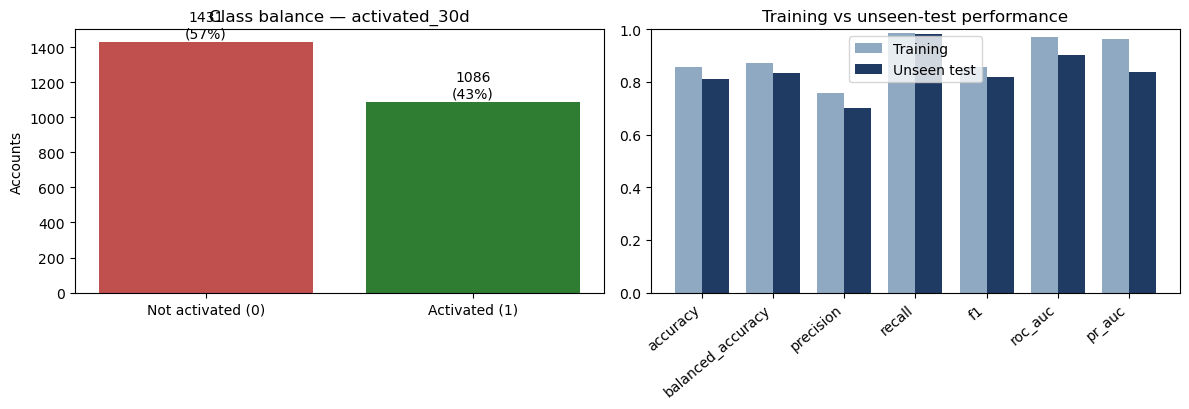

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# (a) Class balance
vc = y.value_counts().sort_index()
axes[0].bar(['Not activated (0)', 'Activated (1)'], vc.values, color=['#C0504D', '#2E7D32'])
for i, v in enumerate(vc.values):
    axes[0].text(i, v + 10, f"{v}\n({100*v/len(y):.0f}%)", ha='center', va='bottom')
axes[0].set_title('Class balance — activated_30d'); axes[0].set_ylabel('Accounts')

# (b) Train vs test metrics
mlist = ['accuracy','balanced_accuracy','precision','recall','f1','roc_auc','pr_auc']
xpos = np.arange(len(mlist)); w = 0.38
axes[1].bar(xpos - w/2, [m_train[k] for k in mlist], w, label='Training', color='#8EA9C1')
axes[1].bar(xpos + w/2, [m_test[k] for k in mlist], w, label='Unseen test', color='#1F3B63')
axes[1].set_xticks(xpos); axes[1].set_xticklabels(mlist, rotation=40, ha='right')
axes[1].set_ylim(0, 1); axes[1].set_title('Training vs unseen-test performance'); axes[1].legend()
plt.tight_layout(); plt.show()

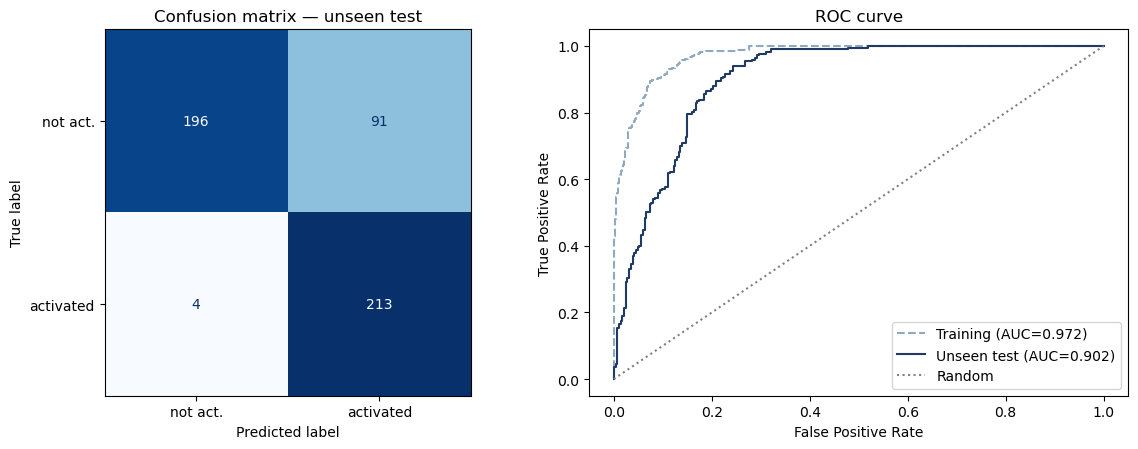

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

# Confusion matrix (unseen test)
ConfusionMatrixDisplay.from_predictions(y_test, pred_te, display_labels=['not act.', 'activated'],
                                        cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Confusion matrix — unseen test')

# ROC curves: training vs test
fpr_tr, tpr_tr, _ = roc_curve(y_trainval, proba_tr)
fpr_te, tpr_te, _ = roc_curve(y_test, proba_te)
axes[1].plot(fpr_tr, tpr_tr, '--', color='#8EA9C1', label=f"Training (AUC={m_train['roc_auc']:.3f})")
axes[1].plot(fpr_te, tpr_te, color='#1F3B63', label=f"Unseen test (AUC={m_test['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], ':', color='grey', label='Random')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC curve'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

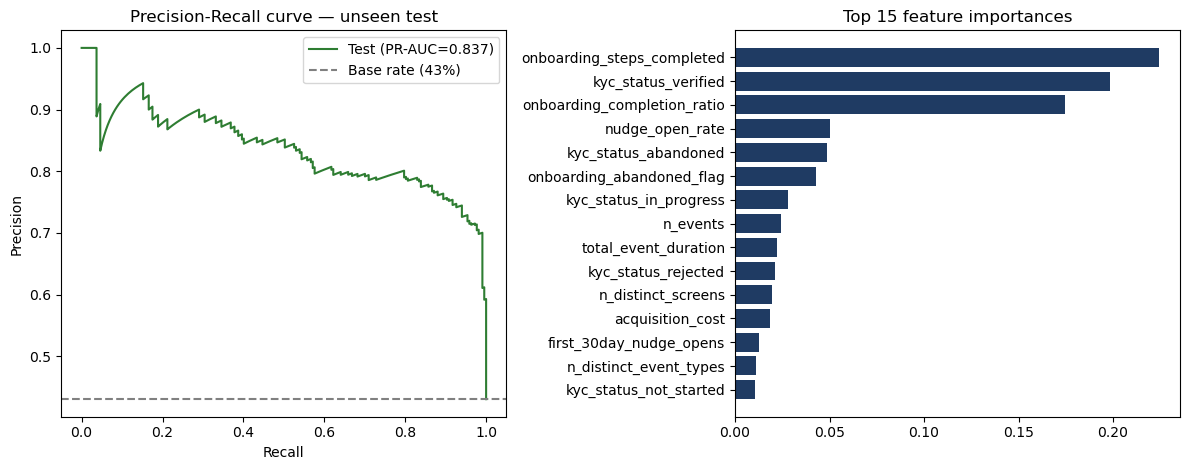

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Precision-Recall curve (unseen test)
prec, rec, _ = precision_recall_curve(y_test, proba_te)
axes[0].plot(rec, prec, color='#2E7D32', label=f"Test (PR-AUC={m_test['pr_auc']:.3f})")
axes[0].axhline(y_test.mean(), ls='--', color='grey', label=f'Base rate ({100*y_test.mean():.0f}%)')
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall curve — unseen test'); axes[0].legend(loc='upper right')

# Feature importances (top 15)
ohe = model.named_steps['prep'].named_transformers_['cat'].named_steps['onehot']
feat_names = numeric_features + list(ohe.get_feature_names_out(categorical_features))
imp = model.named_steps['clf'].feature_importances_
order = np.argsort(imp)[::-1][:15]
axes[1].barh([feat_names[i] for i in order][::-1], [imp[i] for i in order][::-1], color='#1F3B63')
axes[1].set_title('Top 15 feature importances')
plt.tight_layout(); plt.show()

**What the visuals show.** Training and unseen-test ROC curves sit close together, confirming the
model generalises. The feature-importance chart surfaces the behavioural and onboarding signals
(e.g. deposit-attempt behaviour, onboarding completion, nudge engagement) that drive activation
giving STADIOEquities not just a score but an **explanation** of *why* an account is likely to
activate or stall, which is what makes the model actionable for the growth and onboarding teams.

---
*Final method applied: Random Forest (SS2). Target: `activated_30d`. Evaluated on a held-out,
leakage-free test set. See `SS3_PartB_README.md` for how to run this notebook.*